In [55]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from tkinter import *
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

In [57]:
data = pd.read_csv((r"email.csv"), encoding="latin-1")

In [59]:
data.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [61]:
data.shape

(5573, 2)

In [63]:
data.isnull().sum()

Category    0
Message     0
dtype: int64

In [6]:
data.duplicated().sum()

415

In [7]:
data.drop_duplicates(inplace=True)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5158 entries, 0 to 5572
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5158 non-null   object
 1   Message   5158 non-null   object
dtypes: object(2)
memory usage: 120.9+ KB


In [9]:
data["Category"] = data["Category"].map({"ham": 0, "spam": 1})

In [10]:
data.dropna(subset=['Category', 'Message'], inplace=True)

In [11]:
x = data["Message"]
y = data["Category"]

In [12]:
print(data["Category"].isnull().sum())
print(data["Category"].value_counts())

0
Category
0.0    4516
1.0     641
Name: count, dtype: int64


In [13]:
not_spam_count = (data["Category"] == 0).sum()
spam_count = (data["Category"] == 1).sum()

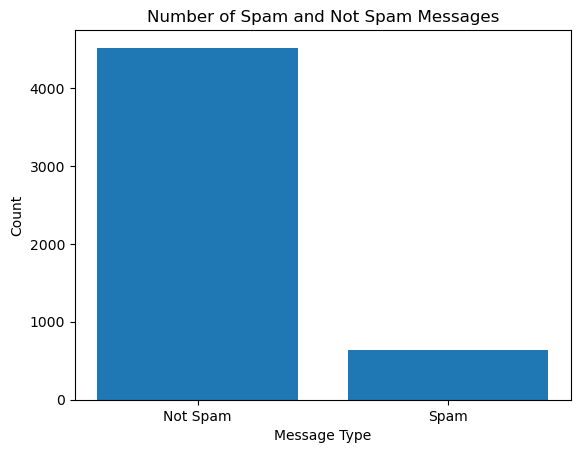

In [14]:
plt.bar(["Not Spam", "Spam"], [not_spam_count, spam_count])
plt.title("Number of Spam and Not Spam Messages")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [16]:
vectorizer = TfidfVectorizer()

In [17]:
x_train = vectorizer.fit_transform(x_train)
x_test = vectorizer.transform(x_test)

In [18]:
model = MultinomialNB()
model.fit(x_train, y_train)

MultinomialNB()

In [20]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy * 100, "%")

Accuracy: 95.25193798449612 %


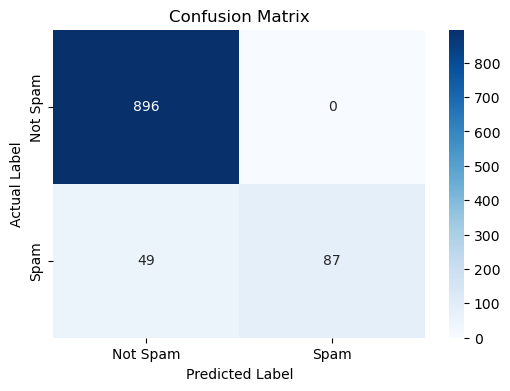

In [21]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [29]:
def check():
    msg = entry.get()

    if msg == "":
        result.config(text="Write a message first", fg="black")
        return

    msg = vectorizer.transform([msg])
    pred = model.predict(msg)[0]

    if pred == 1:
        result.config(text="Spam", fg="red")
    else:
        result.config(text="Not Spam", fg="green")

In [36]:
root = Tk()
root.title("Spam Detection")
root.geometry("420x220")

''

In [40]:
title = Label(root, text="Spam Detection", font=("Arial", 16, "bold"))
title.pack(pady=10)

In [45]:
entry = Entry(root, width=45)
entry.pack(pady=10)

In [46]:
button = Button(root, text="Check", command=check)
button.pack(pady=5)

In [53]:
result = Label(root, text="", font=("Arial", 14, "bold"))
result.pack(pady=10)

In [301]:
acc_label = Label(root, text=f"Accuracy: {accuracy:.2f}")
acc_label.pack()

In [ ]:
root.mainloop()